In [1]:
import pandas as pd

df = pd.read_excel('3TIB_03_ChronicKidneyDisease.xlsx')
print(df.head())

   id  age  bp     sg  al  su     rbc        pc         pcc          ba  ...  \
0   0   48  80  1.020   1   0  normal    normal  notpresent  notpresent  ...   
1   1    7  50  1.020   4   0  normal    normal  notpresent  notpresent  ...   
2   2   62  80  1.010   2   3  normal    normal  notpresent  notpresent  ...   
3   3   48  70  1.005   4   0  normal  abnormal     present  notpresent  ...   
4   4   51  80  1.010   2   0  normal    normal  notpresent  notpresent  ...   

   pcv    wc   rc  htn   dm  cad  appet   pe  ane classification  
0   44  7800  5.2  yes  yes   no   good   no   no            ckd  
1   38  6000  4.8   no   no   no   good   no   no            ckd  
2   31  7500  4.8   no  yes   no   poor   no  yes            ckd  
3   32  6700  3.9  yes   no   no   poor  yes  yes            ckd  
4   35  7300  4.6   no   no   no   good   no   no            ckd  

[5 rows x 26 columns]


TABEL RINGKASAN STATISTIKA DESKRIPTIF (250 PASIEN)
Variabel  Jumlah (n)  Mean (x̄)  Median  Modus  Min   Max  Range   Q1    Q3  Varians (s²)  Std Dev (s)
     age         250      54.56    59.0   60.0  2.0  90.0   88.0 48.0 65.00        292.67        17.11
      bp         250      79.64    80.0   70.0 50.0 180.0  130.0 70.0 90.00        222.76        14.93
      sc         250       4.27     2.2    1.3  0.5  76.0   75.5  1.3  4.25         46.42         6.81


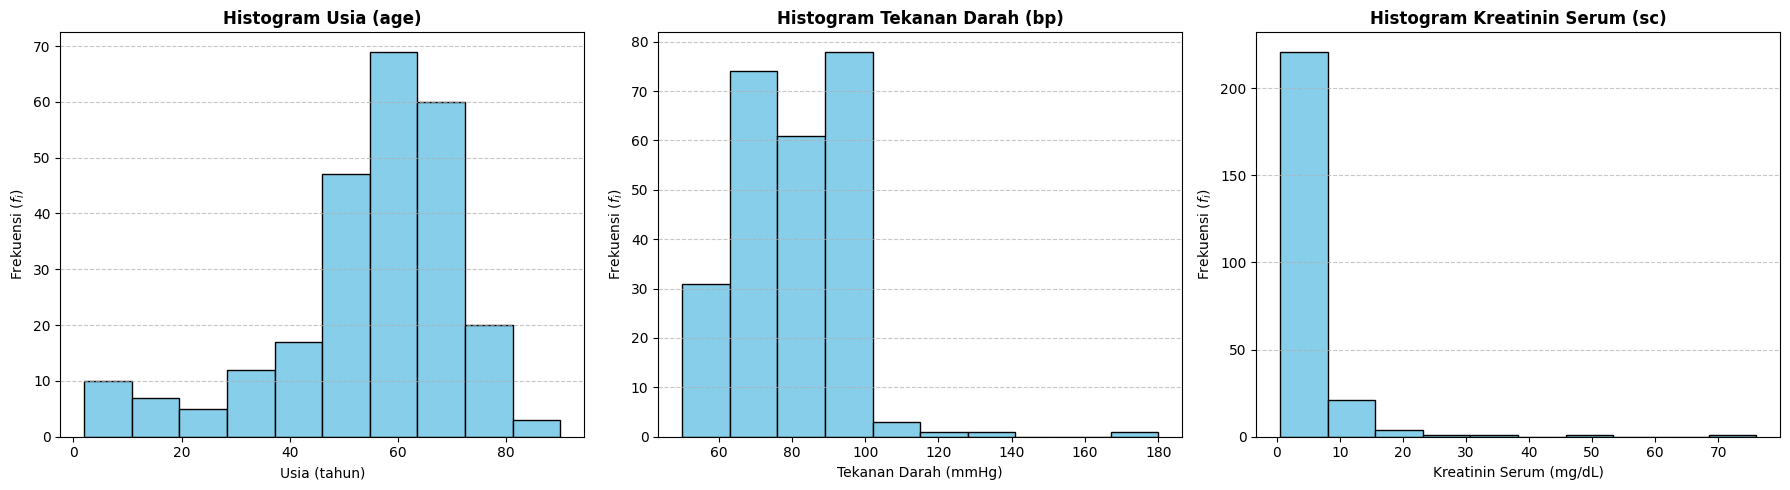

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_excel('3TIB_03_ChronicKidneyDisease.xlsx')
df_250 = df.head(250)

kolom_target = ['age', 'bp', 'sc']

print('=' * 60)
print('TABEL RINGKASAN STATISTIKA DESKRIPTIF (250 PASIEN)')
print('=' * 60)

stats_summary = []

for col in kolom_target:
  data = df_250[col].dropna()
  n = len(data)
  x_mean = data.mean()
  variance = data.var(ddof=1)
  std_dev = data.std(ddof=1)

  minimum = data.min()
  maximum = data.max()
  data_range = maximum - minimum
  q1 = data.quantile(0.25)
  median = data.quantile(0.50)  # Q2
  q3 = data.quantile(0.75)
  mode = data.mode()[0] if not data.mode().empty else np.nan

  stats_summary.append({
      'Variabel': col,
      'Jumlah (n)': n,
      'Mean (x̄)': round(x_mean, 2),
      'Median': round(median, 2),
      'Modus': round(mode, 2),
      'Min': minimum,
      'Max': maximum,
      'Range': data_range,
      'Q1': q1,
      'Q3': q3,
      'Varians (s²)': round(variance, 2),
      'Std Dev (s)': round(std_dev, 2),
  })

df_stats = pd.DataFrame(stats_summary)
print(df_stats.to_string(index=False))
print('=' * 60)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles = [
    'Histogram Usia (age)',
    'Histogram Tekanan Darah (bp)',
    'Histogram Kreatinin Serum (sc)',
]
x_labels = ['Usia (tahun)', 'Tekanan Darah (mmHg)', 'Kreatinin Serum (mg/dL)']

for i, col in enumerate(kolom_target):
  axes[i].hist(
      df_250[col].dropna(), bins=10, color='skyblue', edgecolor='black'
  )
  axes[i].set_title(titles[i], fontsize=12, fontweight='bold')
  axes[i].set_xlabel(x_labels[i], fontsize=10)
  axes[i].set_ylabel('Frekuensi ($f_i$)', fontsize=10)
  axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

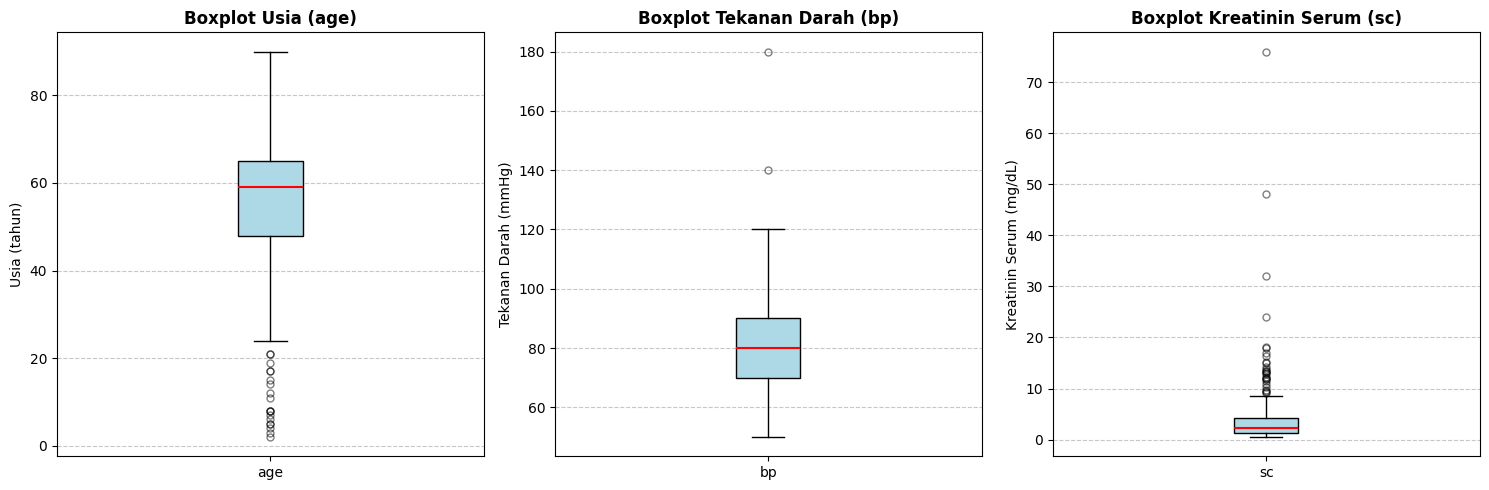

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Membaca file Excel dan mengambil 250 data pertama
df = pd.read_excel('3TIB_03_ChronicKidneyDisease.xlsx')
df_250 = df.head(250)

# Kolom target sesuai dengan dokumen (age, bp, sc)
kolom_target = ['age', 'bp', 'sc']
titles = [
    'Boxplot Usia (age)',
    'Boxplot Tekanan Darah (bp)',
    'Boxplot Kreatinin Serum (sc)',
]
y_labels = ['Usia (tahun)', 'Tekanan Darah (mmHg)', 'Kreatinin Serum (mg/dL)']

# 2. Membuat Visualisasi Boxplot (1 Baris, 3 Kolom)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(kolom_target):
  # Membuat boxplot dengan orientasi vertikal
  bp = axes[i].boxplot(
      df_250[col].dropna(),
      patch_artist=True,
      boxprops=dict(facecolor='lightblue', color='black'),
      medianprops=dict(color='red', linewidth=1.5),
      flierprops=dict(
          marker='o', color='black', alpha=0.5, markersize=5
      ),  # Untuk outlier
  )

  axes[i].set_title(titles[i], fontsize=12, fontweight='bold')
  axes[i].set_ylabel(y_labels[i], fontsize=10)
  axes[i].set_xticklabels([col])  # Label sumbu x
  axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

--- Hasil Uji Normalitas Shapiro-Wilk: Usia (age) ---
Statistik Uji W : 0.9059
p-value         : 2.0504e-11
Keputusan       : H0 ditolak (Data tidak berdistribusi normal, p-value < 0.05)



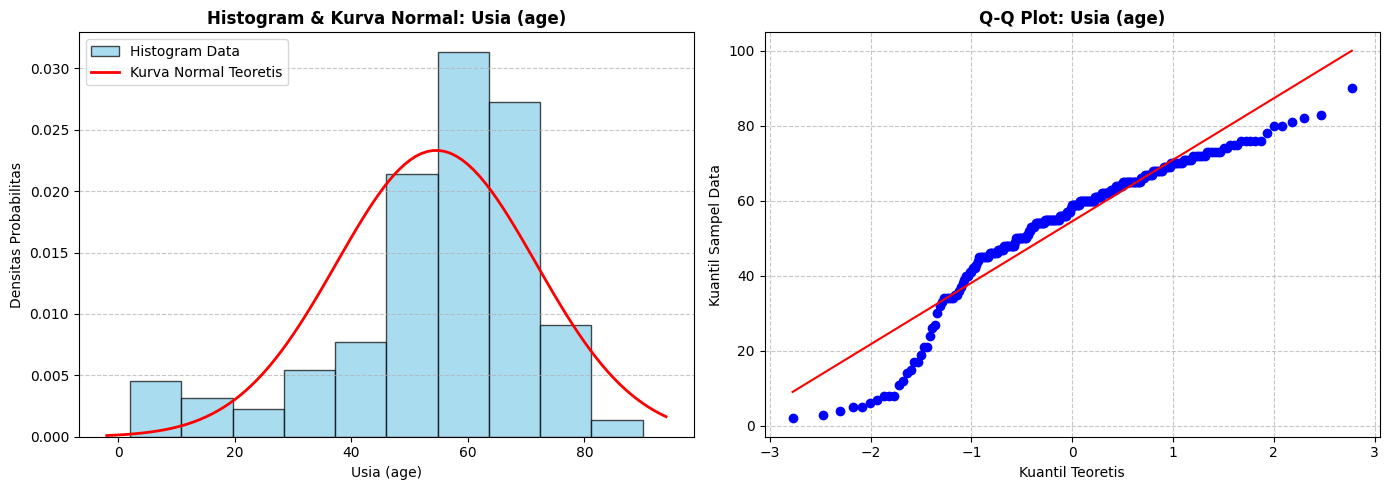

--- Hasil Uji Normalitas Shapiro-Wilk: Tekanan Darah (bp) ---
Statistik Uji W : 0.8763
p-value         : 2.2857e-13
Keputusan       : H0 ditolak (Data tidak berdistribusi normal, p-value < 0.05)



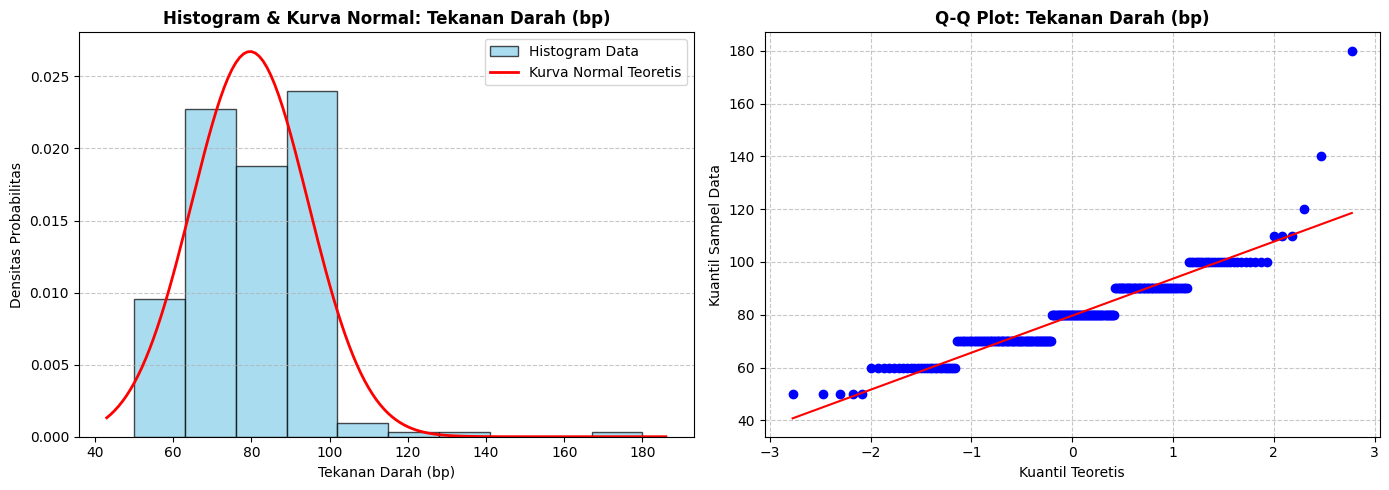

--- Hasil Uji Normalitas Shapiro-Wilk: Kreatinin Serum (sc) ---
Statistik Uji W : 0.4521
p-value         : 5.1031e-27
Keputusan       : H0 ditolak (Data tidak berdistribusi normal, p-value < 0.05)



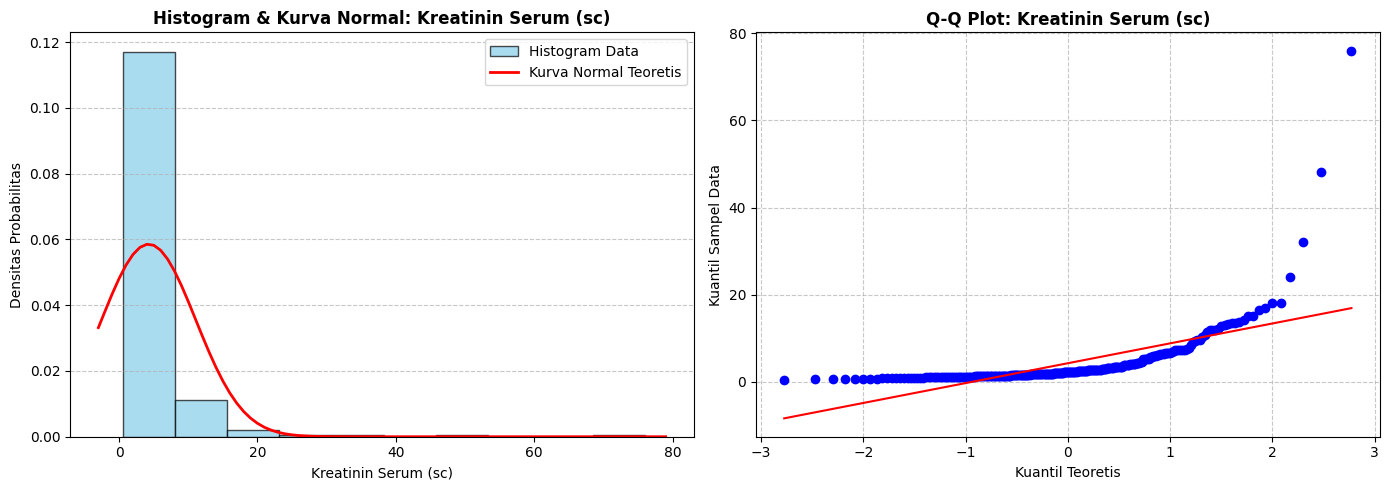

In [6]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd

# 1. Membaca file Excel dan mengambil 250 data pertama
df = pd.read_excel('3TIB_03_ChronicKidneyDisease.xlsx')
df_250 = df.head(250)

# Variabel target sesuai dokumen
kolom_target = ['age', 'bp', 'sc']
labels = ['Usia (age)', 'Tekanan Darah (bp)', 'Kreatinin Serum (sc)']

# 2. Loop untuk melakukan Uji Shapiro-Wilk dan Membuat Visualisasi (Histogram & Q-Q Plot)
for i, col in enumerate(kolom_target):
  data = df_250[col].dropna()

  # Uji Shapiro-Wilk (Persamaan 3-4)
  w_stat, p_value = stats.shapiro(data)

  print(f'--- Hasil Uji Normalitas Shapiro-Wilk: {labels[i]} ---')
  print(f'Statistik Uji W : {w_stat:.4f}')
  print(f'p-value         : {p_value:.4e}')
  if p_value >= 0.05:
    print(
        'Keputusan       : H0 diterima (Data berdistribusi normal, p-value >='
        ' 0.05)\n'
    )
  else:
    print(
        'Keputusan       : H0 ditolak (Data tidak berdistribusi normal,'
        ' p-value < 0.05)\n'
    )

  # Membuat Visualisasi (1 baris untuk Histogram, 1 baris untuk Q-Q Plot)
  fig, axes = plt.subplots(1, 2, figsize=(14, 5))

  # A. Histogram dengan Kurva Normal (Pendukung Visual)
  axes[0].hist(
      data,
      bins=10,
      density=True,
      color='skyblue',
      edgecolor='black',
      alpha=0.7,
      label='Histogram Data',
  )
  # Menambahkan garis kurva distribusi normal teoretis
  xmin, xmax = axes[0].get_xlim()
  x = pd.Series(range(int(xmin), int(xmax) + 1))
  p = stats.norm.pdf(x, data.mean(), data.std())
  axes[0].plot(x, p, 'r-', linewidth=2, label='Kurva Normal Teoretis')

  axes[0].set_title(
      f'Histogram & Kurva Normal: {labels[i]}', fontsize=12, fontweight='bold'
  )
  axes[0].set_xlabel(labels[i], fontsize=10)
  axes[0].set_ylabel('Densitas Probabilitas', fontsize=10)
  axes[0].legend()
  axes[0].grid(axis='y', linestyle='--', alpha=0.7)

  # B. Q-Q Plot (Pendukung Visual)
  stats.probplot(data, dist='norm', plot=axes[1])
  axes[1].set_title(f'Q-Q Plot: {labels[i]}', fontsize=12, fontweight='bold')
  axes[1].set_xlabel('Kuantil Teoretis', fontsize=10)
  axes[1].set_ylabel('Kuantil Sampel Data', fontsize=10)
  axes[1].grid(True, linestyle='--', alpha=0.7)

  plt.tight_layout()
  plt.show()

--- Analisis Korelasi: age vs bp ---
Metode yang Digunakan : Spearman (ρ)
Koefisien Korelasi    : 0.0379
p-value               : 5.5038e-01

--- Analisis Korelasi: age vs sc ---
Metode yang Digunakan : Spearman (ρ)
Koefisien Korelasi    : 0.2165
p-value               : 5.6765e-04

--- Analisis Korelasi: bp vs sc ---
Metode yang Digunakan : Spearman (ρ)
Koefisien Korelasi    : 0.1418
p-value               : 2.4968e-02



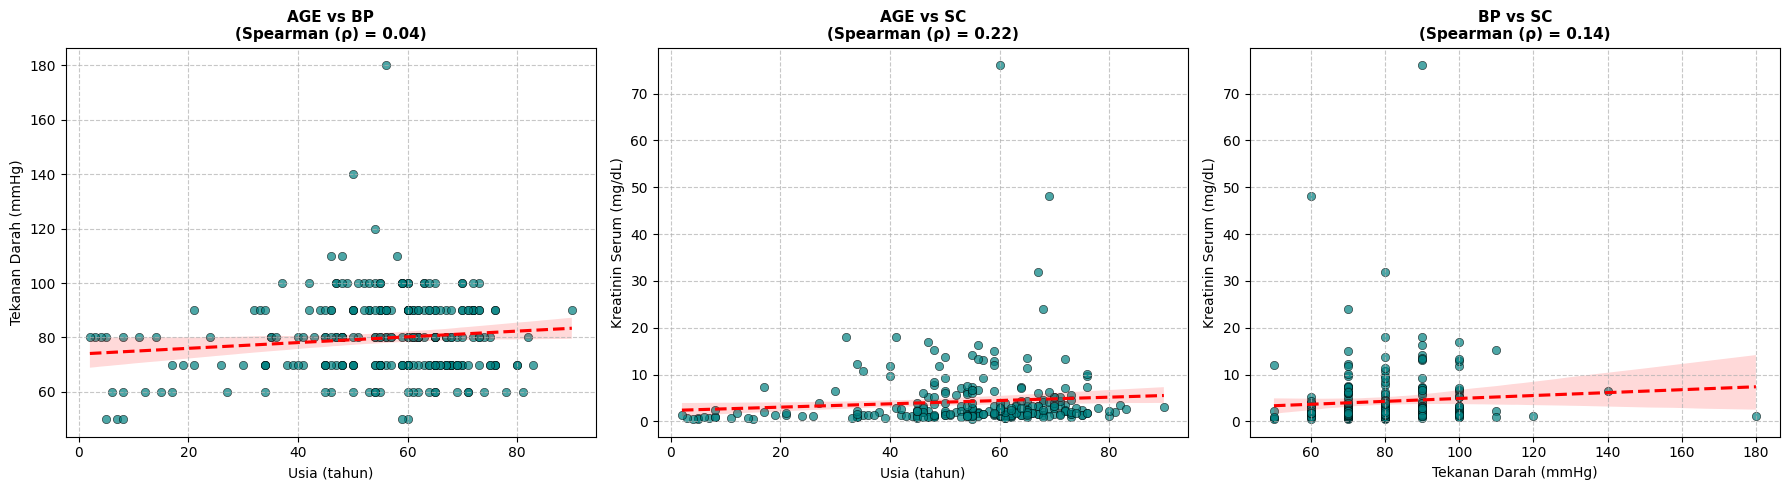

In [7]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import seaborn as sns

# 1. Membaca file Excel dan mengambil 250 data pertama
df = pd.read_excel('3TIB_03_ChronicKidneyDisease.xlsx')
df_250 = df.head(250)

# Pasangan variabel yang akan dianalisis korelasi dan dibuat scatter plot-nya
pasangan_variabel = [('age', 'bp'), ('age', 'sc'), ('bp', 'sc')]

labels = {
    'age': 'Usia (tahun)',
    'bp': 'Tekanan Darah (mmHg)',
    'sc': 'Kreatinin Serum (mg/dL)',
}

# 2. Perhitungan Korelasi & Visualisasi Scatter Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (x_col, y_col) in enumerate(pasangan_variabel):
  data = df_250[[x_col, y_col]].dropna()
  x = data[x_col]
  y = data[y_col]

  # Cek normalitas untuk menentukan penggunaan Pearson (Persamaan 3-5) atau Spearman (Persamaan 3-6)
  _, p_x = stats.shapiro(x)
  _, p_y = stats.shapiro(y)

  if p_x >= 0.05 and p_y >= 0.05:
    # Persamaan 3-5: Korelasi Pearson (r)
    corr, p_val = stats.pearsonr(x, y)
    metode = 'Pearson (r)'
  else:
    # Persamaan 3-6: Korelasi Spearman (rho)
    corr, p_val = stats.spearmanr(x, y)
    metode = 'Spearman (ρ)'

  print(f'--- Analisis Korelasi: {x_col} vs {y_col} ---')
  print(f'Metode yang Digunakan : {metode}')
  print(f'Koefisien Korelasi    : {corr:.4f}')
  print(f'p-value               : {p_val:.4e}\n')

  # Membuat Scatter Plot (Visualisasi Pendukung)
  sns.scatterplot(
      x=x, y=y, ax=axes[i], color='teal', alpha=0.7, edgecolor='k'
  )
  sns.regplot(
      x=x,
      y=y,
      ax=axes[i],
      scatter=False,
      color='red',
      line_kws={'linestyle': '--'},
  )

  axes[i].set_title(
      f'{x_col.upper()} vs {y_col.upper()}\n({metode} = {corr:.2f})',
      fontsize=11,
      fontweight='bold',
  )
  axes[i].set_xlabel(labels[x_col], fontsize=10)
  axes[i].set_ylabel(labels[y_col], fontsize=10)
  axes[i].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import pandas as pd
import scipy.stats as stats

# 1. Membaca file Excel dan mengambil 250 data pertama
df = pd.read_excel('3TIB_03_ChronicKidneyDisease.xlsx')
df_250 = df.head(250)

kolom_target = ['age', 'bp', 'sc']
labels = {
    'age': 'Usia (age)',
    'bp': 'Tekanan Darah (bp)',
    'sc': 'Kreatinin Serum (sc)',
}

print('=' * 80)
print('HASIL PERHITUNGAN STATISTIKA PYTHON (250 PASIEN)')
print('=' * 80)

# --- A. STATISTIKA DESKRIPTIF ---
print('\n[1] TABEL STATISTIKA DESKRIPTIF')
desc_list = []
for col in kolom_target:
  data = df_250[col].dropna()
  n = len(data)
  mean_val = data.mean()  # Persamaan 3-1
  median_val = data.median()
  mode_val = data.mode()[0] if not data.mode().empty else np.nan
  min_val = data.min()
  max_val = data.max()
  range_val = max_val - min_val
  q1 = data.quantile(0.25)
  q3 = data.quantile(0.75)
  var_val = data.var(ddof=1)  # Persamaan 3-2 (s^2)
  std_val = data.std(ddof=1)  # Persamaan 3-3 (s)

  desc_list.append({
      'Variabel': labels[col],
      'n': n,
      'Mean': round(mean_val, 2),
      'Median': round(median_val, 2),
      'Modus': round(mode_val, 2),
      'Min': min_val,
      'Max': max_val,
      'Range': range_val,
      'Q1': round(q1, 2),
      'Q3': round(q3, 2),
      'Varians (s^2)': round(var_val, 2),
      'Std Dev (s)': round(std_val, 2),
  })

df_desc = pd.DataFrame(desc_list)
print(df_desc.to_string(index=False))

# --- B. UJI NORMALITAS (SHAPIRO-WILK) ---
print('\n[2] UJI NORMALITAS SHAPIRO-WILK (alpha = 0.05)')
norm_list = []
for col in kolom_target:
  data = df_250[col].dropna()
  w_stat, p_val = stats.shapiro(data)  # Persamaan 3-4 (W)
  status = (
      'Berdistribusi Normal' if p_val >= 0.05 else 'Tidak Berdistribusi Normal'
  )
  norm_list.append({
      'Variabel': labels[col],
      'Statistik W': round(w_stat, 4),
      'p-value': f'{p_val:.4e}',
      'Kesimpulan': status,
  })
df_norm = pd.DataFrame(norm_list)
print(df_norm.to_string(index=False))

# --- C. ANALISIS KORELASI & PENGUJIAN HIPOTESIS ---
print('\n[3] ANALISIS KORELASI & PENGUJIAN HIPOTESIS (Uji t)')
pairs = [('age', 'bp'), ('age', 'sc'), ('bp', 'sc')]
corr_list = []

for x, y in pairs:
  data = df_250[[x, y]].dropna()
  nx = len(data)

  # Cek normalitas untuk menentukan Pearson atau Spearman
  _, px = stats.shapiro(data[x])
  _, py = stats.shapiro(data[y])

  if px >= 0.05 and py >= 0.05:
    r, p_val = stats.pearsonr(data[x], data[y])  # Persamaan 3-5 (r)
    metode = 'Pearson (r)'
  else:
    r, p_val = stats.spearmanr(data[x], data[y])  # Persamaan 3-6 (rho)
    metode = 'Spearman (rho)'

  # Statistik Uji t (Persamaan 3-7)
  if abs(r) == 1.0:
    t_stat = np.inf
  else:
    t_stat = (r * np.sqrt(nx - 2)) / np.sqrt(1 - r**2)

  hipotesis = (
      'H0 Ditolak (Ada hubungan yang signifikan)'
      if p_val < 0.05
      else 'H0 Diterima (Tidak ada hubungan yang signifikan)'
  )

  # Kriteria Kekuatan Sugiyono (Tabel 3.4)
  abs_r = abs(r)
  if abs_r <= 0.199:
    kekuatan = 'Sangat rendah'
  elif abs_r <= 0.399:
    kekuatan = 'Rendah'
  elif abs_r <= 0.599:
    kekuatan = 'Sedang'
  elif abs_r <= 0.799:
    kekuatan = 'Kuat'
  else:
    kekuatan = 'Sangat kuat'

  corr_list.append({
      'Pasangan': f'{x} - {y}',
      'Metode': metode,
      'Koefisien': round(r, 4),
      't-hitung': round(t_stat, 4),
      'p-value': f'{p_val:.4e}',
      'Kekuatan': kekuatan,
      'Keputusan Uji': hipotesis,
  })

df_corr = pd.DataFrame(corr_list)
print(df_corr.to_string(index=False))
print('=' * 80)

HASIL PERHITUNGAN STATISTIKA PYTHON (250 PASIEN)

[1] TABEL STATISTIKA DESKRIPTIF
            Variabel   n  Mean  Median  Modus  Min   Max  Range   Q1    Q3  Varians (s^2)  Std Dev (s)
          Usia (age) 250 54.56    59.0   60.0  2.0  90.0   88.0 48.0 65.00         292.67        17.11
  Tekanan Darah (bp) 250 79.64    80.0   70.0 50.0 180.0  130.0 70.0 90.00         222.76        14.93
Kreatinin Serum (sc) 250  4.27     2.2    1.3  0.5  76.0   75.5  1.3  4.25          46.42         6.81

[2] UJI NORMALITAS SHAPIRO-WILK (alpha = 0.05)
            Variabel  Statistik W    p-value                 Kesimpulan
          Usia (age)       0.9059 2.0504e-11 Tidak Berdistribusi Normal
  Tekanan Darah (bp)       0.8763 2.2857e-13 Tidak Berdistribusi Normal
Kreatinin Serum (sc)       0.4521 5.1031e-27 Tidak Berdistribusi Normal

[3] ANALISIS KORELASI & PENGUJIAN HIPOTESIS (Uji t)
Pasangan         Metode  Koefisien  t-hitung    p-value      Kekuatan                                    Keputusan Uj